# Actividad — Valores atípicos y EDA con California Housing
**Aprendizaje Supervisado · Unidad 1 · Preparación de datos y análisis exploratorio (EDA)**

**Qué haremos.** En la presentación vimos las herramientas del EDA. Hoy las usarás sobre un conjunto real y, sobre todo,
**tomarás decisiones**: ¿qué hago con cada valor raro? ¿en qué variables puedo confiar para una correlación?

| Parte | Pregunta que responde | Tema de la presentación |
|---|---|---|
| 1 | ¿Qué hay en el conjunto de datos? | Tipos de variable, el dataset |
| 2 | ¿Qué dicen $\bar x$, mediana, $s$, asimetría y curtosis? | Estadística descriptiva |
| 3 | ¿Qué forma tiene cada variable? | Histogramas |
| 4 | ¿Cuántos atípicos marcan los boxplots y la regla del IQR? | Boxplot y $1.5\cdot\mathrm{IQR}$ |
| 5 | ¿Qué son esas filas extremas? ¿error, dato raro o tope? | Un atípico, ¿qué hago con él? |
| 6 | ¿Qué efecto tienen los topes (5.0 y 52)? | Censura |
| 7 | ¿Qué cambia si recorto o aplico logaritmo? | Transformaciones |
| 8 | ¿Cómo se relacionan las variables con el precio? | Análisis bivariado |
| 9 | ¿Qué dice la matriz de correlación? ¿hay multicolinealidad? | Matriz y heatmap |
| 10 | Resumen y entregable | Receta de EDA |

**Tiempo estimado:** 40–50 minutos de trabajo individual.

**Entregable:** este notebook ejecutado, con sus respuestas en las celdas ✏️, y la **tabla de decisiones**
de la Parte 10: *variable · % de atípicos · decisión · justificación*.

**Cómo trabajar.** Ejecuta las celdas en orden. Donde dice ✏️ hay una pregunta o un parámetro que debes cambiar tú
(escribe tus respuestas en la celda de texto que sigue a la pregunta, bajo «**Respuesta:**»).

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
})
AZUL, NARANJA, VERDE, ROJO = "#065A82", "#E07A1F", "#02C39A", "#C0392B"
pd.set_option("display.precision", 3)
warnings.filterwarnings("ignore", message=".*vert.*")   # aviso de versiones nuevas de matplotlib sobre boxplot(vert=...)

---
## Parte 1 — Cargar y conocer los datos

El conjunto **California Housing** (Pace y Barry, 1997) viene del censo de 1990. **Cada fila es un distrito censal**
(no una vivienda): sus valores son medianas o promedios de muchos hogares.

| Variable | Qué describe |
|---|---|
| `MedInc` | ingreso mediano del distrito (en decenas de miles de USD) |
| `HouseAge` | edad mediana de las viviendas (años) |
| `AveRooms` | habitaciones promedio por hogar |
| `AveBedrms` | dormitorios promedio por hogar |
| `Population` | número de habitantes del distrito |
| `AveOccup` | ocupantes promedio por hogar |
| `Latitude`, `Longitude` | ubicación del distrito |
| `MedHouseVal` | **objetivo**: valor mediano de la vivienda (en cientos de miles de USD) |

> La primera vez, `fetch_california_housing` descarga el archivo (≈1 MB) y lo guarda en `~/scikit_learn_data`; se necesita conexión a internet.

In [3]:
data = fetch_california_housing(as_frame=True)
df = data.frame.copy()          # trabajamos sobre una copia: el original queda intacto
print("Forma (filas, columnas):", df.shape)
df.head()

Forma (filas, columnas): (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.0,6.984,1.024,322.0,2.556,37.88,-122.23,4.526
1,8.301,21.0,6.238,0.972,2401.0,2.110,37.86,-122.22,3.585
2,7.257,52.0,8.288,1.073,496.0,2.802,37.85,-122.24,3.521
3,5.643,52.0,5.817,1.073,558.0,2.548,37.85,-122.25,3.413
4,3.846,52.0,6.282,1.081,565.0,2.181,37.85,-122.25,3.422


In [4]:
df.info()
print("\nFaltantes por columna:")
print(df.isna().sum().to_string())
print("\nFilas duplicadas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Faltantes por columna:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0

Filas duplicadas: 0


✏️ **Pregunta 1.1.** ¿Cuántas filas y columnas hay? ¿Hay faltantes o duplicados? ¿Qué tipo de variable es cada columna (continua, discreta…)?

✏️ **Pregunta 1.2.** Cada fila es un *distrito*, no una casa. ¿Qué consecuencia tiene esto cuando una variable dice «promedio» o «mediana»?
(Pista: ¿cómo podría ser un promedio de 140 habitaciones por hogar?)

**Respuesta:**

**1.1.** Hay **20 640 filas y 9 columnas** (8 predictoras + el objetivo `MedHouseVal`). **No hay faltantes ni filas duplicadas.** Todas son `float64`, pero conceptualmente:
- **Continuas:** `MedInc`, `AveRooms`, `AveBedrms`, `AveOccup` (son cocientes/promedios), `Latitude`, `Longitude` y `MedHouseVal`.
- **Discretas (conteos/enteros):** `Population` (número de personas) y `HouseAge` (años enteros, de 1 a 52).
- Ojo: `MedHouseVal`, `HouseAge` y `MedInc` están además **censuradas** en un tope (Parte 6).

**1.2.** Como cada fila es un distrito, `AveRooms`, `AveOccup`, etc. son **cocientes de totales del distrito** (p. ej. habitaciones totales ÷ hogares). Si el distrito tiene muy pocos hogares (denominador pequeño) o no es residencial típico (hotel, resort, cárcel, campus), el cociente se dispara: 140 habitaciones «por hogar» no es una casa con 140 cuartos, sino un distrito con muchas habitaciones (p. ej. cabañas o casas vacacionales vacías) y casi nadie viviendo ahí. Además, describen al *distrito* y no a una vivienda individual (no se puede inferir el comportamiento de una casa a partir del promedio del distrito: falacia ecológica).

---
## Parte 2 — Estadística descriptiva: media, varianza, asimetría y curtosis

Recordatorio (con $z_i = (x_i-\bar x)/s$):

$$\gamma_1=\frac1n\sum_{i=1}^n z_i^3 \quad(\text{asimetría}),\qquad \kappa-3=\frac1n\sum_{i=1}^n z_i^4-3 \quad(\text{curtosis en exceso}).$$

`pandas` calcula ambas con una pequeña corrección para muestras finitas; con $n=20\,640$ la diferencia es mínima.

In [5]:
def resumen(d):
    t = d.agg(["mean", "median", "std", "min", "max"]).T
    t["asimetria"] = d.skew()
    t["curtosis_exc"] = d.kurt()
    t["media - mediana"] = t["mean"] - t["median"]
    return t

resumen(df).round(2)

,mean,median,std,min,max,asimetria,curtosis_exc,media - mediana
MedInc,3.87,3.53,1.90,0.50,15.00,1.65,4.95,0.34
HouseAge,28.64,29.00,12.59,1.00,52.00,0.06,-0.80,-0.36
AveRooms,5.43,5.23,2.47,0.85,141.91,20.70,879.35,0.20
AveBedrms,1.10,1.05,0.47,0.33,34.07,31.20,1628.55,0.05
Population,1425.48,1166.00,1132.46,3.00,35682.00,4.94,73.55,259.48
AveOccup,3.07,2.82,10.39,0.69,1243.33,97.64,10651.01,0.25
Latitude,35.63,34.26,2.14,32.54,41.95,0.47,-1.12,1.37
Longitude,-119.57,-118.49,2.00,-124.35,-114.31,-0.30,-1.33,-1.08
MedHouseVal,2.07,1.80,1.15,0.15,5.00,0.98,0.33,0.27


In [6]:
# Comprobación «a mano» con MedInc: lo que hace pandas, paso por paso
x = df["MedInc"]
z = (x - x.mean()) / x.std(ddof=0)          # puntaje z
g1 = (z ** 3).mean()                         # asimetría
exceso = (z ** 4).mean() - 3                 # curtosis en exceso
print(f"a mano : asimetría = {g1:.4f}   curtosis en exceso = {exceso:.4f}")
print(f"pandas : asimetría = {x.skew():.4f}   curtosis en exceso = {x.kurt():.4f}")

a mano : asimetría = 1.6465   curtosis en exceso = 4.9510
pandas : asimetría = 1.6467   curtosis en exceso = 4.9525


In [7]:
# ¿Qué variables tienen la forma «más rara»? ordenamos por |asimetría|
resumen(df)[["asimetria", "curtosis_exc"]].abs().sort_values("asimetria", ascending=False).round(1)

,asimetria,curtosis_exc
AveOccup,97.6,10651.0
AveBedrms,31.2,1628.5
AveRooms,20.7,879.4
Population,4.9,73.6
MedInc,1.6,5.0
MedHouseVal,1.0,0.3
Latitude,0.5,1.1
Longitude,0.3,1.3
HouseAge,0.1,0.8


✏️ **Pregunta 2.1.** En `MedInc`, ¿qué signo tiene `media - mediana`? ¿Concuerda con el signo de la asimetría? Explícalo con una frase.

✏️ **Pregunta 2.2.** Menciona las **tres variables** con mayor asimetría. ¿Qué dice la curtosis de la que tiene el valor más grande?
(Recuerda: la curtosis alta habla de *colas pesadas*, es decir, de valores extremos.)

✏️ **Pregunta 2.3.** `AveOccup` tiene media ≈ 3 pero un máximo de más de 1 000. ¿Cuántas desviaciones estándar por encima de la media está ese máximo? Calcúlalo en la celda de abajo.

**Respuesta:**

**2.1.** En `MedInc`, `media − mediana = +0.34` (media 3.87 > mediana 3.53), y la asimetría es **+1.65**. Concuerdan: la cola derecha (pocos distritos de ingreso muy alto) jala la media hacia arriba, mientras que la mediana no se mueve.

**2.2.** Las tres con mayor asimetría: **`AveOccup` (≈97.6), `AveBedrms` (≈31) y `AveRooms` (≈20.7)**. La curtosis en exceso de `AveOccup` es **≈10 651**, enorme (una normal tiene 0): la distribución es un pico estrecho alrededor de 3 con **colas extremadamente pesadas**, es decir, un puñado de valores lejísimos que dominan los momentos de orden 3 y 4.

**2.3.** El máximo de `AveOccup` (≈1 243 ocupantes por hogar) está a **≈119 desviaciones estándar** de la media. Y eso que la propia $s$ (10.4) ya está inflada por esos atípicos; en una normal, algo a más de 5–6 $s$ prácticamente no ocurre nunca.

In [8]:
# ✏️ Pregunta 2.3: puntaje z del valor máximo de AveOccup
v = df["AveOccup"]
z_max = (v.max() - v.mean()) / v.std()
print(f"El máximo de AveOccup está a {z_max:.0f} desviaciones estándar de la media")

El máximo de AveOccup está a 119 desviaciones estándar de la media


---
## Parte 3 — Forma de cada variable: histogramas

Dibujamos la media (naranja, discontinua) y la mediana (verde). Para poder **ver** la forma, recortamos el 0.5 % superior
*solo en el dibujo* (los datos no se modifican).

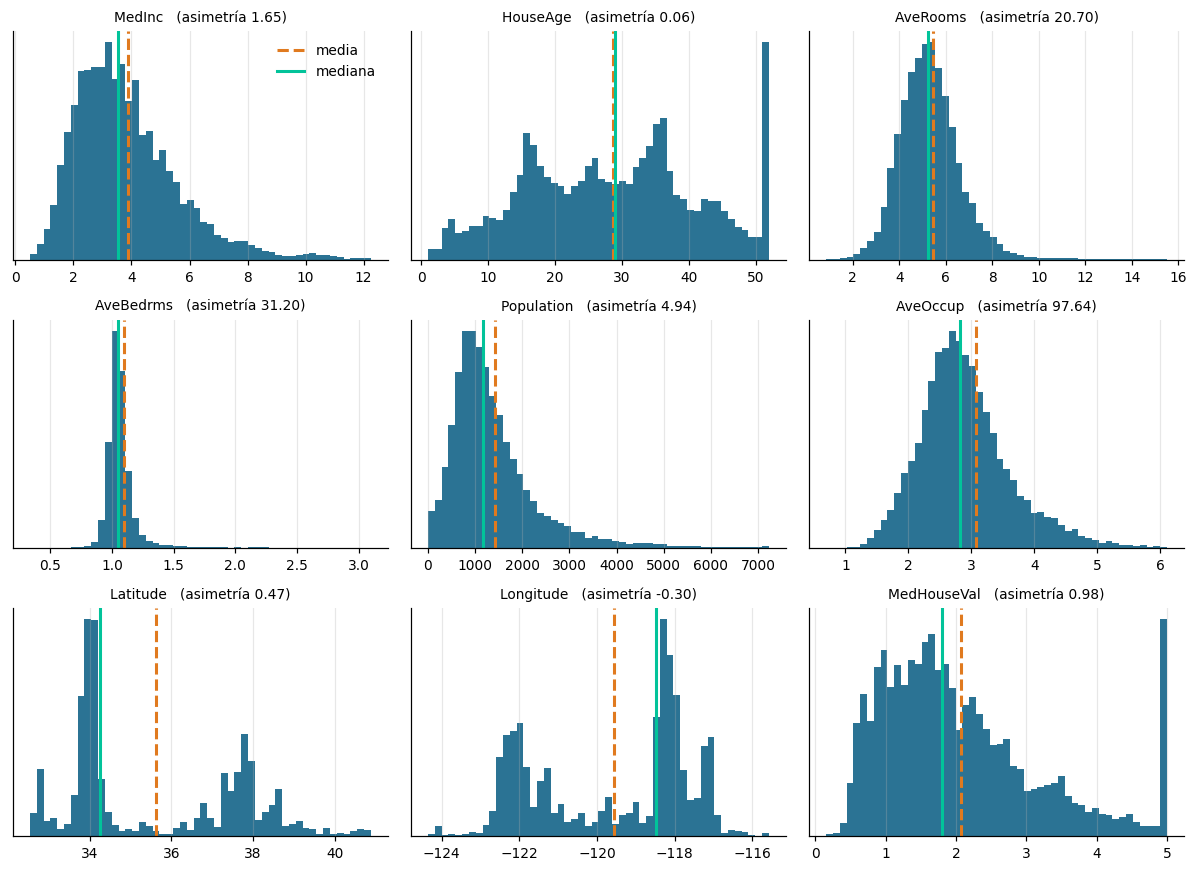

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for ax, c in zip(axes.ravel(), df.columns):
    x = df[c]
    tope = x.quantile(0.995)                       # ✏️ prueba con 1.0 para AveOccup y compara
    ax.hist(x[x <= tope], bins=50, color=AZUL, alpha=0.85)
    ax.axvline(x.mean(), color=NARANJA, lw=2, ls="--", label="media")
    ax.axvline(x.median(), color=VERDE, lw=2, label="mediana")
    ax.set_title(f"{c}   (asimetría {x.skew():.2f})", fontsize=9)
    ax.set_yticks([])
axes[0, 0].legend(frameon=False)
plt.tight_layout()
plt.show()

✏️ **Pregunta 3.1.** Describe con una frase la forma de `MedInc`, `HouseAge`, `Population` y `MedHouseVal`.
¿Cuáles tienen una barra «de más» al extremo derecho? (La estudiaremos en la Parte 6.)

✏️ **Pregunta 3.2.** Cambia `tope = x.quantile(0.995)` por `x.quantile(1.0)` y mira `AveOccup`. ¿Qué pasa con el histograma y por qué?

**Respuesta:**

**3.1.**
- `MedInc`: unimodal con **sesgo a la derecha** (la mayoría entre 2 y 5; cola larga hacia ingresos altos), con una pequeña acumulación en 15 (tope).
- `HouseAge`: aproximadamente **simétrica/plana** (multimodal, de 1 a 52), con una **barra de más en 52**.
- `Population`: **muy sesgada a la derecha** (la mayoría < 3 000, cola larga hasta 35 682).
- `MedHouseVal`: sesgada a la derecha con una **barra de más en 5.0**.

Las que tienen la barra «de más» al extremo derecho son `HouseAge` (52) y `MedHouseVal` (5.0); en menor medida `MedInc` (15).

**3.2.** Con `x.quantile(1.0)` el recorte deja de existir y el eje x se estira hasta ≈1 243. Como 50 bins se reparten entre 0 y 1 243, cada bin mide ≈25 ocupantes: **casi todos los datos (que están entre 1 y 6) caen en la primera barra** y el resto se ve vacío. El histograma ya no muestra la forma real; lo controlan unas pocas observaciones extremas. Por eso conviene recortar *en el dibujo* (o usar escala log) para ver la forma.

---
## Parte 4 — Identificar atípicos con boxplots y la regla del IQR

**Regla de Tukey.** Con $Q_1$, $Q_3$ y $\mathrm{IQR}=Q_3-Q_1$, un dato es atípico si cae fuera de

$$[\,Q_1-k\cdot\mathrm{IQR},\ \ Q_3+k\cdot\mathrm{IQR}\,],\qquad k=1.5\ (\text{atípico})\quad\text{o}\quad k=3\ (\text{atípico extremo}).$$

Primero comprobamos con datos simulados qué fracción marca la regla cuando **sí** conocemos la distribución.

In [10]:
def cercas_iqr(s, k=1.5):
    '''Devuelve (cerca inferior, cerca superior) de la regla de Tukey.'''
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rng = np.random.default_rng(0)
for nombre, x in [("normal", rng.normal(size=100_000)), ("lognormal", rng.lognormal(size=100_000))]:
    lo, hi = cercas_iqr(pd.Series(x))
    print(f"{nombre:10s}: {100 * ((x < lo) | (x > hi)).mean():.2f} % de los datos fuera de las cercas")

normal    : 0.72 % de los datos fuera de las cercas
lognormal : 7.82 % de los datos fuera de las cercas


✏️ **Pregunta 4.1.** En la normal, ¿qué porcentaje marca la regla? ¿Y en la lognormal (muy asimétrica)? ¿Qué te dice esto sobre interpretar
«porcentaje de atípicos» en variables con cola larga?

**Respuesta:**

**4.1.** En la normal la regla marca **≈0.7 %** (el valor teórico es 0.70 %). En la lognormal marca **≈7.8 %**, más de diez veces más, aunque **ninguno es un error**: son parte natural de una distribución con cola larga.

Conclusión: el «porcentaje de atípicos» por IQR solo tiene una interpretación clara si la distribución es aproximadamente simétrica. En variables con cola larga, un porcentaje alto suele reflejar **la forma de la distribución**, no datos malos. Hay que mirar qué tan lejos están y qué son esas filas antes de decidir.

In [11]:
def tabla_atipicos(d, k=1.5):
    filas = []
    for c in d.columns:
        lo, hi = cercas_iqr(d[c], k)
        bajo, alto = int((d[c] < lo).sum()), int((d[c] > hi).sum())
        filas.append(dict(variable=c, cerca_inf=lo, cerca_sup=hi, n_bajo=bajo, n_alto=alto,
                          pct_atipicos=100 * (bajo + alto) / len(d), minimo=d[c].min(), maximo=d[c].max()))
    return pd.DataFrame(filas).set_index("variable")

K = 1.5                        # ✏️ cambia a 3.0 y vuelve a ejecutar esta celda y la siguiente
tabla = tabla_atipicos(df, K)
tabla.round(2)

,cerca_inf,cerca_sup,n_bajo,n_alto,pct_atipicos,minimo,maximo
variable,,,,,,,
MedInc,-0.71,8.01,0,681,3.30,0.50,15.00
HouseAge,-10.50,65.50,0,0,0.00,1.00,52.00
AveRooms,2.02,8.47,45,466,2.48,0.85,141.91
AveBedrms,0.86,1.24,231,1271,7.28,0.33,34.07
Population,-620.00,3132.00,0,1196,5.79,3.00,35682.00
AveOccup,1.15,4.56,7,704,3.44,0.69,1243.33
Latitude,28.26,43.38,0,0,0.00,32.54,41.95
Longitude,-127.48,-112.33,0,0,0.00,-124.35,-114.31
MedHouseVal,-0.98,4.82,0,1071,5.19,0.15,5.00


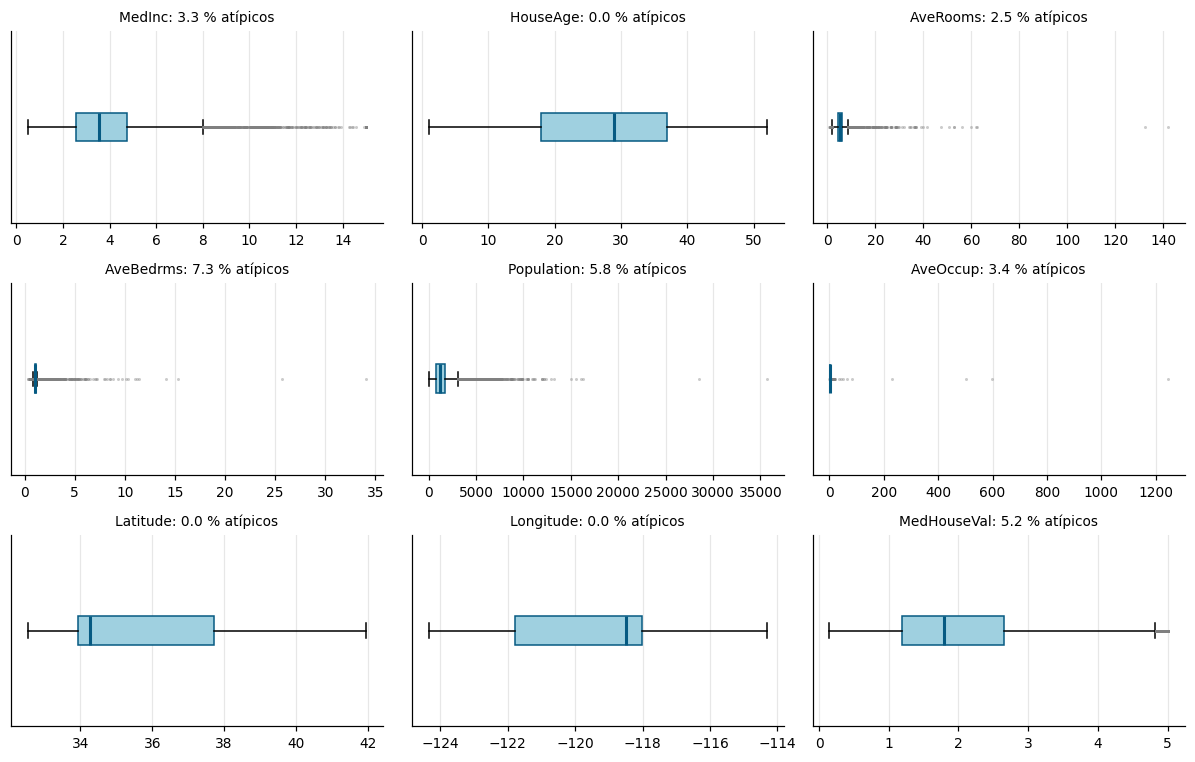

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(11, 7))
for ax, c in zip(axes.ravel(), df.columns):
    ax.boxplot(df[c], vert=False, whis=K, patch_artist=True,
               boxprops=dict(facecolor="#9FD0E0", edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
               flierprops=dict(marker="o", markersize=2, markerfacecolor="gray", markeredgecolor="none", alpha=0.4))
    ax.set_yticks([])
    ax.set_title(f"{c}: {tabla.loc[c, 'pct_atipicos']:.1f} % atípicos", fontsize=9)
plt.tight_layout()
plt.show()

In [13]:
# ✏️ Pregunta 4.3: misma tabla con k = 3 (atípicos extremos)
tabla_atipicos(df, 3.0).round(2)

,cerca_inf,cerca_sup,n_bajo,n_alto,pct_atipicos,minimo,maximo
variable,,,,,,,
MedInc,-3.98,11.28,0,140,0.68,0.50,15.00
HouseAge,-39.00,94.00,0,0,0.00,1.00,52.00
AveRooms,-0.39,10.89,0,180,0.87,0.85,141.91
AveBedrms,0.72,1.38,47,701,3.62,0.33,34.07
Population,-2027.00,4539.00,0,421,2.04,3.00,35682.00
AveOccup,-0.13,5.84,0,132,0.64,0.69,1243.33
Latitude,22.59,49.05,0,0,0.00,32.54,41.95
Longitude,-133.17,-106.64,0,0,0.00,-124.35,-114.31
MedHouseVal,-3.16,7.00,0,0,0.00,0.15,5.00


✏️ **Pregunta 4.2.** Con $k=1.5$: ¿qué variable tiene el mayor *porcentaje* de atípicos? ¿Cuál tiene el valor más **lejano** (compara `maximo` con `cerca_sup`)?
¿Coinciden? ¿Por qué un porcentaje alto no implica necesariamente valores absurdos?

✏️ **Pregunta 4.3.** Repite con $k=3$. ¿Qué variables casi «se limpian» y cuáles conservan atípicos extremos? ¿Cuáles tienen **0 %** y por qué
(piensa en `Latitude`, `Longitude` y `HouseAge`)?

**Respuesta:**

**4.2.** Con $k=1.5$, el mayor **porcentaje** lo tiene `AveBedrms` (≈7 %), seguida de `Population` (5.8 %) y `MedHouseVal` (5.2 %). El valor **más lejano** relativo a su cerca es `AveOccup`: su máximo (1 243) está ≈**270 veces** por encima de la cerca superior (4.56); en `AveBedrms` ≈27 veces, en `AveRooms` ≈17 y en `Population` ≈11.

**No coinciden.** Un porcentaje alto con valores cercanos a la cerca indica una cola larga pero plausible (p. ej. distritos grandes en `Population`, o los 5.0 censurados de `MedHouseVal`); uno o pocos valores absurdamente lejanos pueden dar un porcentaje bajo. El porcentaje mide **cuántos** salen de la caja, no **cuán raros** son.

**4.3.** Con $k=3$ (ver celda añadida abajo):
- Casi se «limpian»: `MedInc` (3.3 % → 0.7 %), `AveOccup` (3.4 % → 0.6 %), `AveRooms` (2.5 % → 0.9 %) y **`MedHouseVal` queda en 0 %** (la cerca sube a 7.0 y el tope está en 5.0).
- Conservan atípicos extremos: `AveBedrms` (≈3.6 %) y `Population` (2.0 %), y aunque `AveOccup` y `AveRooms` tengan porcentajes bajos, **sus máximos siguen estando órdenes de magnitud fuera de la cerca**.
- Con **0 %** en ambos $k$: `Latitude`, `Longitude` y `HouseAge`. Son variables **acotadas** por construcción: las coordenadas están limitadas por la geografía de California y `HouseAge` va de 1 a 52 (el tope corta la cola). Su rango completo cae dentro de las cercas.

---
## Parte 5 — Inspeccionar las filas extremas: ¿error, dato raro o tope?

La regla del IQR dice **qué es inusual**, no **qué es incorrecto**. Para decidir hay que mirar las filas y razonar con el contexto.
Una pista útil: el número de hogares de un distrito es aproximadamente `Population / AveOccup`.

In [14]:
ext = df.nlargest(5, "AveOccup").copy()
ext["hogares (aprox.)"] = ext["Population"] / ext["AveOccup"]
print("Las 5 filas con más ocupantes por hogar:")
ext[["Population", "AveOccup", "hogares (aprox.)", "AveRooms", "MedHouseVal"]].round(1)

Las 5 filas con más ocupantes por hogar:


,Population,AveOccup,hogares (aprox.),AveRooms,MedHouseVal
19006,7460.0,1243.3,6.0,3.2,1.4
3364,4198.0,599.7,7.0,5.1,0.7
16669,6532.0,502.5,13.0,9.1,3.5
13034,6675.0,230.2,29.0,8.3,2.2
9172,8733.0,83.2,105.0,5.1,1.5


In [15]:
ext2 = df.nlargest(5, "AveRooms").copy()
ext2["hogares (aprox.)"] = ext2["Population"] / ext2["AveOccup"]
print("Las 5 filas con más habitaciones por hogar:")
ext2[["Population", "AveOccup", "hogares (aprox.)", "AveRooms", "AveBedrms", "MedHouseVal"]].round(1)

Las 5 filas con más habitaciones por hogar:


,Population,AveOccup,hogares (aprox.),AveRooms,AveBedrms,MedHouseVal
1914,30.0,2.7,11.0,141.9,25.6,5.0
1979,36.0,2.4,15.0,132.5,34.1,1.6
12447,83.0,1.8,45.0,62.4,14.1,0.9
1913,112.0,2.3,48.0,61.8,11.0,4.4
11862,28.0,1.8,16.0,59.9,15.3,0.7


✏️ **Pregunta 5.1.** Para cada uno de estos casos, clasifícalo y justifica: **(a)** error de captura / imposible, **(b)** dato real pero raro,
**(c)** tope o censura. Fíjate en los hogares aproximados: un distrito con 7 460 personas y ≈6 hogares, ¿qué tipo de lugar podría ser?
(pista: residencias universitarias, cárceles, cuarteles…) ¿Qué distritos con muchas habitaciones por hogar y muy poca población podrían ser?

✏️ **Pregunta 5.2.** ¿Tienen sentido estos distritos para un modelo que predice el **valor de la vivienda** en zonas residenciales normales?
Propón una regla (por ejemplo, un mínimo de hogares) para marcarlos o excluirlos, **y anota cuántas filas afectaría**.

**Respuesta:**

**5.1.** Clasificación de los casos extremos:

| caso | datos | clasificación | razonamiento |
|---|---|---|---|
| `AveOccup` = 1 243 (7 460 hab., ≈6 hogares) | fila 19006 | **(b) dato real pero raro** (posible problema de captura en «hogares») | 7 460 personas en 6 hogares no son viviendas: es población en **alojamiento colectivo** (cárcel, cuartel, residencia universitaria) que el censo cuenta como personas pero no como hogares. |
| `AveOccup` = 600 y 502 (4 198 y 6 532 hab., 7 y 13 hogares) | | **(b)** | mismo patrón: instituciones con población grande y casi sin hogares. |
| `AveOccup` = 230 y 83 | | **(b)** | colectivos más pequeños (bases, campus) mezclados con algo de vivienda. |
| `AveRooms` = 142 y 132 (30–36 hab., 11–15 hogares) | | **(b)** | muy poca población y muchísimas habitaciones por hogar: zonas de **casas vacacionales / resorts / cabañas** donde la mayoría de las viviendas no tienen residentes permanentes, o predios con hoteles. El numerador incluye viviendas desocupadas y el denominador solo hogares ocupados. |
| `MedHouseVal` = 5.0 en la fila 1914 | | **(c) tope** | valor censurado en 500 000 USD. |

Ninguno parece **(a) imposible** en sentido estricto (no hay negativos ni ceros absurdos), pero sí son **mediciones que no significan lo mismo** que en un distrito residencial típico, porque el cociente se calcula con muy pocos hogares.

**5.2.** No mucho: un modelo de valor de vivienda para zonas residenciales normales no debería aprender de cárceles, cuarteles o zonas de cabañas vacías; además estos pocos puntos distorsionan medias, $s$ y $r$. Regla propuesta: **marcar como «no residencial típico» los distritos con menos de 10 hogares** (`Population/AveOccup < 10`). Afecta **51 filas de 20 640 (0.25 %)**. (Con umbral 20 serían 119 filas; con 5, solo 12.) Preferiría **marcarlos con un indicador** y excluirlos del entrenamiento del modelo «residencial», documentando la regla, en vez de borrarlos sin dejar rastro.

In [16]:
# ✏️ Pregunta 5.2: prueba tu regla aquí (ejemplo: marcar distritos con menos de 10 hogares)
hogares = df["Population"] / df["AveOccup"]
marca = hogares < 10
print(f"Filas marcadas: {marca.sum()} de {len(df)}  ({100 * marca.mean():.2f} %)")
df.loc[marca, ["Population", "AveOccup", "AveRooms", "MedHouseVal"]].describe().round(1)

Filas marcadas: 51 de 20640  (0.25 %)


,Population,AveOccup,AveRooms,MedHouseVal
count,51.0,51.0,51.0,51.0
mean,253.3,40.2,6.4,2.1
std,1183.8,191.0,4.8,1.4
min,3.0,0.8,1.0,0.1
25%,13.0,2.5,3.3,0.8
50%,20.0,3.3,5.1,1.8
75%,32.0,4.9,7.1,3.5
max,7460.0,1243.3,24.5,5.0


---
## Parte 6 — Topes (censura): los picos en 5.0 y 52

En los histogramas había una barra extra al final de `MedHouseVal` y de `HouseAge`: valores **truncados** por la forma en que se publicó
el censo (valores mayores se registran como el tope). No son «atípicos»: son datos **censurados**.

MedHouseVal :   992 filas ≥ 5.0  (4.81 %)
HouseAge    :  1273 filas ≥ 52  (6.17 %)
MedInc      :    51 filas ≥ 15.0  (0.25 %)


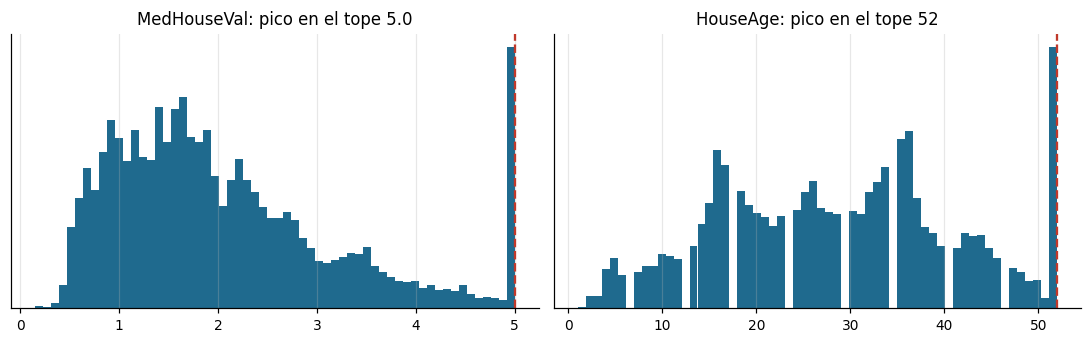

In [17]:
topes = {"MedHouseVal": 5.0, "HouseAge": 52, "MedInc": 15.0}
for c, tope in topes.items():
    n = int((df[c] >= tope).sum())
    print(f"{c:12s}: {n:5d} filas ≥ {tope}  ({100 * n / len(df):.2f} %)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, c in zip(axes, ["MedHouseVal", "HouseAge"]):
    ax.hist(df[c], bins=60, color=AZUL, alpha=0.9)
    ax.axvline(topes[c], color=ROJO, ls="--", lw=1.5)
    ax.set_title(f"{c}: pico en el tope {topes[c]}")
    ax.set_yticks([])
plt.tight_layout()
plt.show()

In [18]:
# ¿Cómo cambia una correlación si «quitamos» las filas con tope?
sin_tope = df[df["MedHouseVal"] < 5.0]
print("r(MedInc, MedHouseVal) con topes :", round(df["MedInc"].corr(df["MedHouseVal"]), 3))
print("r(MedInc, MedHouseVal) sin topes :", round(sin_tope["MedInc"].corr(sin_tope["MedHouseVal"]), 3))
print("Filas que se perderían:", len(df) - len(sin_tope))

r(MedInc, MedHouseVal) con topes : 0.688
r(MedInc, MedHouseVal) sin topes : 0.647
Filas que se perderían: 992


✏️ **Pregunta 6.1.** ¿Por qué no es lo mismo un tope que un atípico? ¿Cuántos distritos tienen `MedHouseVal` en el tope? ¿Y `HouseAge`?

✏️ **Pregunta 6.2.** La correlación baja al quitar los topes. ¿Significa que «con topes» está mal? Pista: los distritos más caros e ingresos más altos son
justo los que fueron truncados. ¿Qué **sesgo** introduce *borrar* esas filas? Propón una alternativa (por ejemplo, agregar un indicador `es_tope`
o reportar el desempeño del modelo también en la zona no truncada).

**Respuesta:**

**6.1.** Un **atípico** es un valor real (o erróneo) que cae lejos del resto; un **tope** es un valor que **no es el verdadero**: el dato real es *mayor o igual* al tope, pero se registró como el tope por la forma en que se publicó el censo. Es información incompleta (censura), no un valor extremo. Prueba de ello: con $k=3$ la regla del IQR **no** marca ninguno de los 5.0 de `MedHouseVal`; el problema no es la distancia sino la acumulación artificial.

- `MedHouseVal` en el tope (5.0): **992 distritos (4.81 %)**.
- `HouseAge` en el tope (52): **1 273 distritos (6.17 %)**.
- (Además, `MedInc` en 15: 51 distritos, 0.25 %).

**6.2.** No, no está «mal»: la correlación con topes (0.688) usa todos los distritos; sin topes baja a 0.647. Pero **borrar las 992 filas introduce un sesgo de selección**: elimina justo los distritos más caros y de mayor ingreso, recortando el rango de ambas variables (restricción de rango), lo que **atenúa artificialmente la correlación** y produce un modelo que nunca vio la parte alta del mercado (subestimará sistemáticamente los distritos caros).

Alternativas:
- Conservar las filas y agregar un indicador **`es_tope = (MedHouseVal >= 5.0)`** (y análogos para `HouseAge = 52`, `MedInc = 15`).
- Reportar el desempeño del modelo **por separado** en la zona no truncada y en la truncada; en la truncada, interpretar la predicción como «≥ 500 000».
- Usar modelos para datos censurados (p. ej. regresión Tobit) o tratar el problema como clasificación «¿supera el tope?» + regresión para el resto.

---
## Parte 7 — Transformar o recortar: ¿qué cambia?

Tres tratamientos habituales para colas largas:

| Tratamiento | Qué hace | Cuándo es razonable |
|---|---|---|
| **Winsorizar** (`clip`) | trunca en las cercas del IQR | los extremos son raros/dudosos pero no queremos perder filas |
| **Logaritmo** | comprime la cola derecha | variable positiva con cola larga y efectos multiplicativos |
| **Nada** | deja el dato igual | el valor extremo es real y relevante |

In [19]:
def logaritmo(s):
    # conteos (pueden valer 0): log(1 + x); promedios estrictamente positivos: log(x)
    return np.log1p(s) if s.name == "Population" else np.log(s)

def efecto(c, k=3.0):
    x = df[c]
    lo, hi = cercas_iqr(x, k)
    variantes = {
        "original": x,
        f"clip (k={k})": x.clip(lo, hi),
        "log": logaritmo(x),
    }
    filas = []
    for nombre, v in variantes.items():
        filas.append(dict(version=nombre, asimetria=v.skew(), curtosis_exc=v.kurt(), r_con_objetivo=v.corr(df["MedHouseVal"]),
                          spearman=v.corr(df["MedHouseVal"], method="spearman")))
    return pd.DataFrame(filas).set_index("version"), variantes

for c in ["AveOccup", "AveRooms", "Population"]:
    t, _ = efecto(c)
    print(f"── {c}")
    print(t.round(3).to_string(), "\n")

── AveOccup
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original         97.640     10651.011          -0.024    -0.257
clip (k=3.0)      0.963         1.654          -0.271    -0.257
log               2.128        34.634          -0.256    -0.257 

── AveRooms
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original         20.698       879.353           0.152     0.263
clip (k=3.0)      0.888         2.235           0.288     0.263
log               0.868         8.901           0.240     0.263 

── Population
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original          4.936        73.553          -0.025     0.004
clip (k=3.0)      1.505         2.519          -0.030     0.004
log              -1.044         4.484          -0.021     0.00

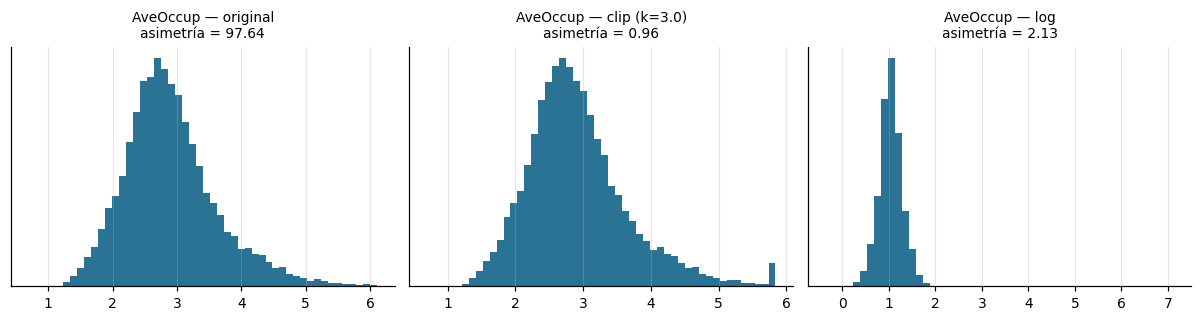

In [20]:
t, var = efecto("AveOccup")
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, (nombre, v) in zip(axes, var.items()):
    tope = v.quantile(0.995) if nombre == "original" else v.max()
    ax.hist(v[v <= tope], bins=50, color=AZUL, alpha=0.85)
    ax.set_title(f"AveOccup — {nombre}\nasimetría = {v.skew():.2f}", fontsize=9)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

In [21]:
# ✏️ Pregunta 7.3: mismo análisis con un recorte más agresivo (k = 1.5)
for c in ["AveOccup", "AveRooms", "Population"]:
    t15, _ = efecto(c, k=1.5)
    lo, hi = cercas_iqr(df[c], 1.5)
    lo3, hi3 = cercas_iqr(df[c], 3.0)
    pct15 = 100 * ((df[c] < lo) | (df[c] > hi)).mean()
    pct3 = 100 * ((df[c] < lo3) | (df[c] > hi3)).mean()
    print(f"── {c}: filas modificadas por el recorte  k=1.5 → {pct15:.2f} %   |   k=3 → {pct3:.2f} %")
    print(t15.round(3).to_string(), "\n")

── AveOccup: filas modificadas por el recorte  k=1.5 → 3.44 %   |   k=3 → 0.64 %
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original         97.640     10651.011          -0.024    -0.257
clip (k=1.5)      0.510         0.007          -0.281    -0.257
log               2.128        34.634          -0.256    -0.257 

── AveRooms: filas modificadas por el recorte  k=1.5 → 2.48 %   |   k=3 → 0.87 %
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                                        
original         20.698       879.353           0.152     0.263
clip (k=1.5)      0.349         0.089           0.311     0.264
log               0.868         8.901           0.240     0.263 

── Population: filas modificadas por el recorte  k=1.5 → 5.79 %   |   k=3 → 2.04 %
              asimetria  curtosis_exc  r_con_objetivo  spearman
version                                        

✏️ **Pregunta 7.1.** Mira `AveOccup`: ¿qué le pasa a la correlación de Pearson con `MedHouseVal` al recortar? ¿Y a la de Spearman?
¿Qué te dice eso sobre lo que hacían los valores extremos con $r$? (Pista: el logaritmo y el recorte casi no cambian el *orden* de los datos; ¿por qué Spearman casi no se mueve?)

✏️ **Pregunta 7.2.** Para `Population` el logaritmo deja la asimetría **negativa**. ¿Qué significa que se haya «pasado»? ¿Es un problema?

✏️ **Pregunta 7.3.** Cambia `k` en `efecto(c, k=3.0)` por `1.5` y compara. ¿Cuánta información pierdes al recortar con un $k$ más agresivo?

**Respuesta:**

**7.1.** En `AveOccup` la **correlación de Pearson** con `MedHouseVal` pasa de **−0.024** (original) a **−0.271** al recortar (y a −0.256 con log), mientras que la de **Spearman queda en −0.257** en las tres versiones. Los valores extremos estaban **aplastando $r$**: unos pocos puntos con `AveOccup` de cientos dominaban la covarianza y ocultaban una relación negativa real (más personas por hogar → viviendas más baratas). Spearman no se mueve porque usa **rangos**: el recorte y el logaritmo son transformaciones monótonas (no decrecientes) que **no cambian el orden** de los datos (el recorte solo produce empates arriba de la cerca), así que los rangos prácticamente no cambian.

**7.2.** Con log, `Population` queda con asimetría **≈ −1.04**: el logaritmo comprimió tanto la cola derecha que ahora la cola larga está a la **izquierda** (distritos con muy poca población, 3–50 personas, se separan mucho en escala log). «Se pasó» de corrección. No es grave: la asimetría bajó en magnitud (4.9 → 1.0) y la curtosis de 73.6 a 4.5; la mayoría de los modelos no requiere simetría perfecta. Pero conviene saber que los distritos diminutos (muchos son los mismos casos raros de la Parte 5) ahora son los «atípicos». Si molesta, una transformación más suave (raíz cuadrada, Box-Cox/Yeo-Johnson) podría quedar más cerca de 0.

**7.3.** Con $k=1.5$ (celda añadida abajo) se recorta mucho más: en `AveOccup` se modifican **3.4 %** de las filas (vs 0.6 % con $k=3$), en `AveRooms` 2.5 % (vs 0.9 %) y en `Population` **5.8 %** (vs 2.0 %). La asimetría baja más (p. ej. `AveOccup` 0.96 → 0.51) y $r$ apenas cambia (−0.271 → −0.281), pero **se pierde información real**: cientos de distritos legítimos (grandes o con hogares numerosos) quedan aplastados en el mismo valor y ya no se distinguen entre sí. Spearman no cambia, señal de que el beneficio adicional es pequeño. $k=3$ es un compromiso más prudente.

### Aplicar sus decisiones

Completa el diccionario con la acción que elijas para cada variable: `"ninguno"`, `"clip"` o `"log"`.
La función `aplicar` crea una copia transformada; luego comparamos la asimetría antes y después.

> ⚠️ **Fugas.** Aquí calculamos las cercas con *todos* los datos para simplificar. En un proyecto real, las cercas (y medias, etc.) se
> calculan **solo con el conjunto de entrenamiento** y se reutilizan en validación y prueba (como vimos en la sesión 1).

In [22]:
decisiones = {        # ✏️ cambia las decisiones y vuelve a ejecutar esta celda y las siguientes
    "MedInc": "ninguno",
    "HouseAge": "ninguno",
    "AveRooms": "clip",
    "AveBedrms": "clip",
    "Population": "log",
    "AveOccup": "clip",
    "Latitude": "ninguno",
    "Longitude": "ninguno",
}

def aplicar(d, decisiones, k=3.0):
    out = d.copy()
    for c, accion in decisiones.items():
        if accion == "clip":
            out[c] = out[c].clip(*cercas_iqr(out[c], k))
        elif accion == "log":
            out[c] = logaritmo(out[c])
        elif accion != "ninguno":
            raise ValueError(f"acción desconocida para {c}: {accion!r}")
    return out

df_t = aplicar(df, decisiones)
comp = pd.DataFrame({"asimetria_antes": df.skew(), "asimetria_despues": df_t.skew(),
                     "curtosis_antes": df.kurt(), "curtosis_despues": df_t.kurt()})
comp.round(2)

,asimetria_antes,asimetria_despues,curtosis_antes,curtosis_despues
MedInc,1.65,1.65,4.95,4.95
HouseAge,0.06,0.06,-0.80,-0.80
AveRooms,20.70,0.89,879.35,2.23
AveBedrms,31.20,1.11,1628.55,2.60
Population,4.94,-1.04,73.55,4.48
AveOccup,97.64,0.96,10651.01,1.65
Latitude,0.47,0.47,-1.12,-1.12
Longitude,-0.30,-0.30,-1.33,-1.33
MedHouseVal,0.98,0.98,0.33,0.33


---
## Parte 8 — Análisis bivariado

Con $n=20\,640$ puntos, una dispersión simple se **satura** (puntos encimados). Comparamos con un *hexbin*, que cuenta puntos por celda,
y miramos `MedHouseVal` por grupos de ingreso.

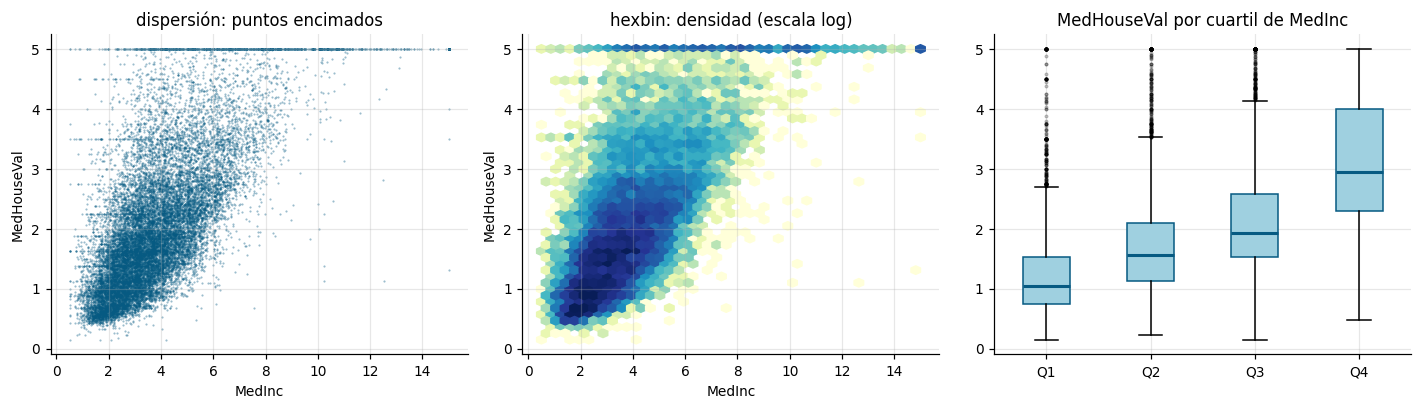

r de Pearson = 0.688    rho de Spearman = 0.677


In [23]:
X_NOMBRE = "MedInc"        # ✏️ cambia la variable y vuelve a ejecutar (prueba AveOccup, HouseAge, Latitude…)
Y_NOMBRE = "MedHouseVal"

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].scatter(df[X_NOMBRE], df[Y_NOMBRE], s=2, color=AZUL, alpha=0.4, lw=0)
axes[0].set_title("dispersión: puntos encimados")
hb = axes[1].hexbin(df[X_NOMBRE], df[Y_NOMBRE], gridsize=40, cmap="YlGnBu", mincnt=1, bins="log")
axes[1].set_title("hexbin: densidad (escala log)")
grupos = pd.qcut(df[X_NOMBRE], 4, labels=["Q1", "Q2", "Q3", "Q4"])
axes[2].boxplot([df.loc[grupos == g, Y_NOMBRE] for g in grupos.cat.categories], patch_artist=True,
                boxprops=dict(facecolor="#9FD0E0", edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
                flierprops=dict(markersize=1.5, alpha=0.3))
axes[2].set_xticklabels(grupos.cat.categories)
axes[2].set_title(f"{Y_NOMBRE} por cuartil de {X_NOMBRE}")
for ax in axes[:2]:
    ax.set_xlabel(X_NOMBRE); ax.set_ylabel(Y_NOMBRE)
plt.tight_layout()
plt.show()
print(f"r de Pearson = {df[X_NOMBRE].corr(df[Y_NOMBRE]):.3f}    rho de Spearman = {df[X_NOMBRE].corr(df[Y_NOMBRE], method='spearman'):.3f}")

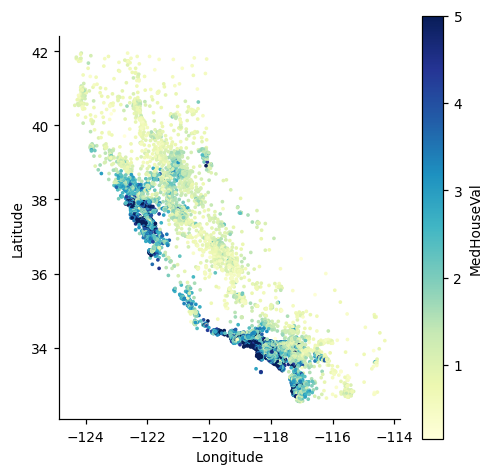

In [24]:
# Mapa: la ubicación también cuenta
plt.figure(figsize=(5, 5))
sc = plt.scatter(df["Longitude"], df["Latitude"], c=df["MedHouseVal"], s=2, cmap="YlGnBu")
plt.colorbar(sc, label="MedHouseVal")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.gca().set_aspect(1.2)
plt.grid(False)
plt.show()

✏️ **Pregunta 8.1.** En la primera gráfica (`MedInc` vs `MedHouseVal`), ¿qué es la línea horizontal de puntos arriba? ¿Cómo la relacionas con la Parte 6?
¿Qué ventaja da el hexbin sobre la dispersión?

✏️ **Pregunta 8.2.** ¿Cómo cambia la mediana de `MedHouseVal` al pasar de Q1 a Q4 de ingreso? ¿Es monótona?

✏️ **Pregunta 8.3.** En el mapa, ¿dónde están los distritos más caros? ¿Qué otro factor (distinto de `MedInc`)
podría estar influyendo tanto en el ingreso como en el precio? (recuerda *correlación ≠ causalidad*)

**Respuesta:**

**8.1.** La línea horizontal de puntos arriba son los **992 distritos censurados en `MedHouseVal` = 5.0** (Parte 6): su valor real es ≥ 500 000 USD pero quedaron todos registrados en el tope, aunque tengan ingresos muy distintos. (Se ven también líneas más tenues en 3.5, 4.5, etc., valores redondeados frecuentes). El **hexbin** muestra la **densidad**: en la dispersión, miles de puntos encimados forman una mancha uniforme y no se ve dónde se concentran los datos; el hexbin (con escala log) revela que la mayoría está en ingresos 2–5 y valores 1–2.5, y la relación creciente se ve con claridad.

**8.2.** La mediana de `MedHouseVal` crece de forma **monótona** con el ingreso: **Q1 ≈ 1.04 → Q2 ≈ 1.56 → Q3 ≈ 1.93 → Q4 ≈ 2.95** (cientos de miles de USD). Del primer al último cuartil casi se triplica, y el salto es mayor entre Q3 y Q4 (la relación se acelera en ingresos altos). La dispersión también crece en los cuartiles altos, donde además se concentran los topes.

**8.3.** Los distritos más caros están en la **costa**: el Área de la Bahía de San Francisco y la franja costera de Los Ángeles–San Diego. El interior (Valle Central, desierto) es mucho más barato. El factor de fondo es la **ubicación / cercanía al mar y a los centros de empleo**: influye tanto en quién vive ahí (ingreso) como en el precio del suelo. Es una posible **variable confusora**: la correlación ingreso–precio no implica que subir el ingreso de un distrito subiría el precio; ambos pueden deberse en parte a la ubicación.

---
## Parte 9 — Matriz de correlación, heatmap y multicolinealidad

Con 9 variables hay $\binom92=36$ pares. La matriz $R=\frac1{n-1}Z^\top Z$ (con $Z$ las columnas estandarizadas) los resume.
Seguimos las buenas prácticas de la presentación: escala **divergente centrada en 0**, solo el **triángulo inferior** y **valores anotados**.

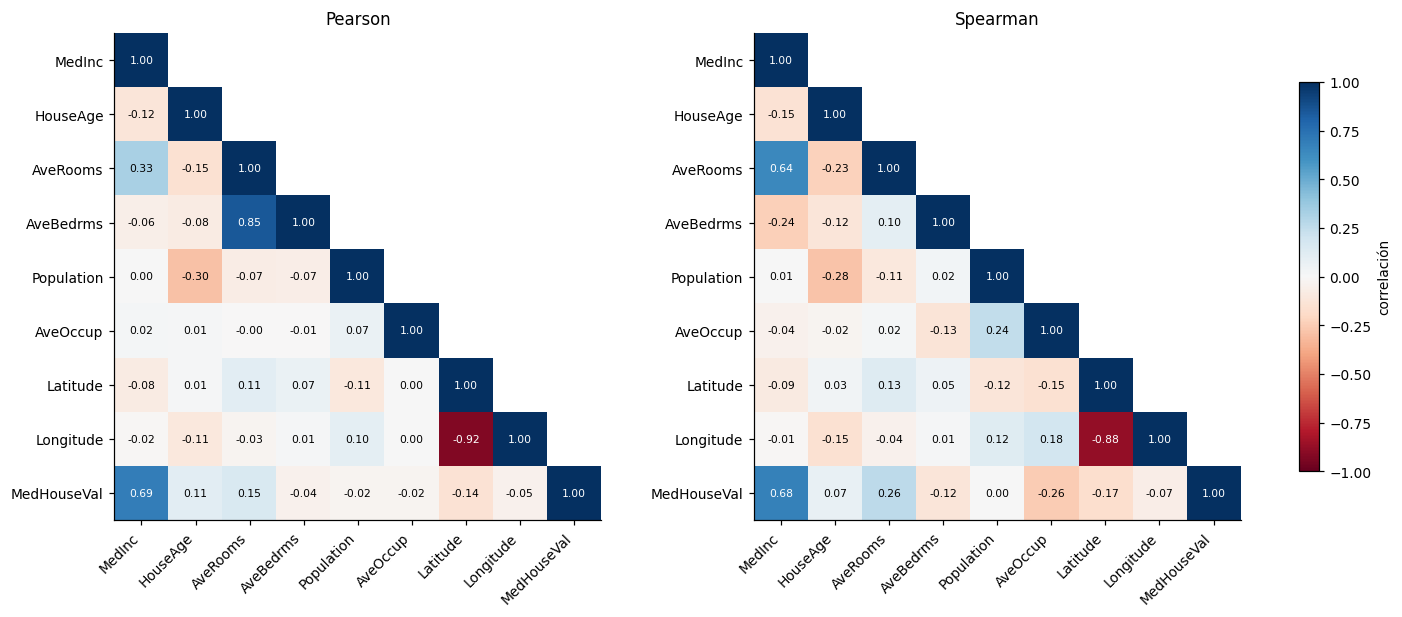

In [25]:
def heatmap(Cm, ax, titulo):
    mask = np.triu(np.ones(Cm.shape, dtype=bool), k=1)           # oculta el triángulo superior (es repetido)
    im = ax.imshow(np.ma.array(Cm.values, mask=mask), cmap="RdBu", vmin=-1, vmax=1)
    n = len(Cm)
    ax.set_xticks(range(n)); ax.set_xticklabels(Cm.columns, rotation=45, ha="right")
    ax.set_yticks(range(n)); ax.set_yticklabels(Cm.index)
    ax.grid(False)
    for i in range(n):
        for j in range(i + 1):
            v = Cm.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
    ax.set_title(titulo)
    return im

Cp = df.corr()                         # Pearson
Cs = df.corr(method="spearman")        # Spearman = Pearson de los rangos
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
heatmap(Cp, axes[0], "Pearson")
im = heatmap(Cs, axes[1], "Spearman")
fig.colorbar(im, ax=axes, shrink=0.8, label="correlación")
plt.show()

In [26]:
# Los pares más fuertes (sin repetir y sin la diagonal)
tri = np.tril(np.ones(Cp.shape, dtype=bool), k=-1)
pares = Cp.where(tri).stack().rename("pearson").to_frame()
pares["spearman"] = Cs.where(tri).stack()
pares["|pearson|"] = pares["pearson"].abs()
pares.sort_values("|pearson|", ascending=False).head(6).round(2)

,,pearson,spearman,|pearson|
Longitude,Latitude,-0.92,-0.88,0.92
AveBedrms,AveRooms,0.85,0.10,0.85
MedHouseVal,MedInc,0.69,0.68,0.69
AveRooms,MedInc,0.33,0.64,0.33
Population,HouseAge,-0.30,-0.28,0.30
AveRooms,HouseAge,-0.15,-0.23,0.15


In [27]:
# Pearson vs Spearman con el objetivo: ¿en qué variables difieren más?
vs = pd.DataFrame({"pearson": Cp["MedHouseVal"], "spearman": Cs["MedHouseVal"]}).drop("MedHouseVal")
vs["diferencia"] = (vs["spearman"] - vs["pearson"]).abs()
vs.sort_values("diferencia", ascending=False).round(2)

,pearson,spearman,diferencia
AveOccup,-0.02,-0.26,0.23
AveRooms,0.15,0.26,0.11
AveBedrms,-0.04,-0.12,0.08
HouseAge,0.11,0.07,0.03
Population,-0.02,0.00,0.03
Longitude,-0.05,-0.07,0.02
Latitude,-0.14,-0.17,0.02
MedInc,0.69,0.68,0.01


✏️ **Pregunta 9.1.** ¿Qué variable se correlaciona más con el objetivo? ¿Cuál es el par de variables **predictoras** más correlacionado (Pearson)? ¿Y el segundo?
¿Tienen sentido en el contexto (geografía, tamaño de las viviendas)?

✏️ **Pregunta 9.2.** ¿En qué variable difieren más Pearson y Spearman con el objetivo? Mira también el par `AveBedrms`–`AveRooms`: ¿qué le pasa a su correlación al pasar de Pearson a Spearman?
Conecta con lo que viste en las Partes 4, 5 y 7: ¿qué estaban haciendo los atípicos con $r$? ¿Qué implica para decir que dos variables son «redundantes»?

**Respuesta:**

**9.1.** La variable más correlacionada con el objetivo es **`MedInc`** ($r = 0.69$, $\rho = 0.68$). Entre predictoras, el par más correlacionado es **`Latitude`–`Longitude` ($r = -0.92$)** y el segundo **`AveBedrms`–`AveRooms` ($r = 0.85$)**. Ambos tienen sentido:
- California está «inclinada» de noroeste a sureste: al ir al norte también vas al oeste, así que las coordenadas de los distritos caen sobre una diagonal (y la población se concentra en la costa).
- Más habitaciones por hogar implica, mecánicamente, más dormitorios por hogar (los dormitorios son un subconjunto de las habitaciones, y ambos usan el mismo denominador, hogares).

**9.2.** Con el objetivo, la mayor diferencia está en **`AveOccup`** (Pearson −0.02 vs Spearman −0.26), seguida de `AveRooms` (0.15 vs 0.26). Y el par **`AveBedrms`–`AveRooms` se desploma de $r = 0.85$ a $\rho \approx 0.10$**.

Conexión: igual que en las Partes 4, 5 y 7, los pocos distritos extremos (cabañas/resorts con 100+ habitaciones y 25–34 dormitorios por hogar; instituciones con 1 000 ocupantes por hogar) **controlan $r$**: en `AveOccup` lo aplastan hacia 0, y en `AveBedrms`–`AveRooms` lo **inflan**, porque unos cuantos puntos alineados muy lejos dominan la covarianza. Para el 99 % de los distritos la relación es débil. Implicación: **no hay que declarar dos variables «redundantes» solo por un $r$ alto**; hay que confirmarlo con Spearman, con gráficas y tras tratar los atípicos.

### Multicolinealidad

Con predictores muy correlacionados, los coeficientes de una regresión lineal se vuelven inestables. El **factor de inflación de la varianza**
mide qué tan bien se explica cada predictor con los demás:

$$\mathrm{VIF}_j=\frac{1}{1-R_j^2}\;=\;\big[R^{-1}\big]_{jj}\quad(\text{el }j\text{-ésimo elemento de la diagonal de la inversa de la matriz de correlación}).$$

Regla práctica: $\mathrm{VIF}>5$–$10$ es una alerta.

In [28]:
def vif(X):
    R = X.corr().values
    return pd.Series(np.diag(np.linalg.inv(R)), index=X.columns, name="VIF")

X = df.drop(columns="MedHouseVal")
vif(X).round(1)

MedInc        2.5
HouseAge      1.2
AveRooms      8.3
AveBedrms     7.0
Population    1.1
AveOccup      1.0
Latitude      9.3
Longitude     9.0
Name: VIF, dtype: float64

✏️ **Pregunta 9.3.** ¿Qué variables tienen VIF alto? ¿Las habías anticipado con el heatmap? ¿Esa colinealidad es «real» para todo el conjunto o la crean unos pocos distritos extremos? (revisa los Spearman de la Parte 9)

✏️ **Pregunta 9.4.** Quita **una** de las variables con VIF alto (la que consideres más redundante, p. ej. `AveBedrms`) en la celda de abajo y vuelve a calcular.
¿Cuánto baja el VIF de su «pareja»? ¿Qué variable elegirías conservar y por qué?

**Respuesta:**

**9.3.** VIF alto (> 5): **`Latitude` (9.3), `Longitude` (9.0), `AveRooms` (8.3) y `AveBedrms` (≈7.0)**. Sí se anticipaban: son exactamente los dos pares con mayor $|r|$ del heatmap. Pero son de naturaleza distinta:
- **Latitude–Longitude:** colinealidad **real** para todo el conjunto (Spearman −0.88, casi igual a Pearson). Es la geografía de California.
- **AveRooms–AveBedrms:** la **crean unos pocos distritos extremos**: con Spearman la correlación es ≈0.10. (Con la matriz de Spearman los VIF de estas dos bajarían a ≈2.5 y ≈1.3.)

**9.4.** Al quitar `AveBedrms`, el VIF de `AveRooms` baja de **8.3 a 1.3**; `MedInc` también baja (2.5 → 1.3), porque formaba parte de la misma relación lineal. Latitude/Longitude siguen ≈8.7–8.8, como era de esperar. Conservaría **`AveRooms`**: tiene mayor correlación con el objetivo (0.15 vs −0.05 en Pearson; 0.26 vs −0.12 en Spearman) y mayor relación con `MedInc`, mientras `AveBedrms` aporta poca información adicional. (Otra opción sería crear el cociente `AveBedrms / AveRooms`, la proporción de dormitorios, que sí agrega información distinta.) Para Latitude/Longitude **no** quitaría ninguna: juntas codifican la ubicación, que es clave para el precio; para un modelo lineal se podrían transformar (p. ej. distancia a la costa o a SF/LA) y para un árbol la colinealidad no es problema.

In [29]:
# ✏️ Pregunta 9.4: elige qué variable quitar y compara
a_quitar = ["AveBedrms"]
vif(X.drop(columns=a_quitar)).round(1)

MedInc        1.3
HouseAge      1.2
AveRooms      1.3
Population    1.1
AveOccup      1.0
Latitude      8.8
Longitude     8.7
Name: VIF, dtype: float64

---
## Parte 10 — Resumen y entregable

Rellena la tabla con **una fila por variable predictora**. La columna `pct_atipicos` ya está calculada con la regla del IQR ($k=1.5$);
las columnas `decision` y `justificacion` las completas tú.

| variable | % atípicos | decisión | justificación |
|---|---|---|---|
| *(ejemplo)* `AveOccup` | 3.4 | `clip` en $3\cdot$IQR | casi todos los distritos tienen ≈3 ocupantes; los valores > 50 corresponden a distritos con muy pocos hogares (residencias colectivas) y arrastran la media y a $r$ |

Una buena justificación responde: **¿por qué es (o no) un error?**, **¿qué pasaría con el análisis si lo dejamos?** y **¿cómo documento la decisión?**

In [30]:
entrega = tabla_atipicos(df.drop(columns="MedHouseVal"), 1.5)[["pct_atipicos"]].round(1).copy()
entrega["decision"] = "(completa: ninguno / clip / log / excluir / indicador)"
entrega["justificacion"] = "(completa)"
pd.set_option("display.max_colwidth", 80)
entrega

,pct_atipicos,decision,justificacion
variable,,,
MedInc,3.3,(completa: ninguno / clip / log / excluir / indicador),(completa)
HouseAge,0.0,(completa: ninguno / clip / log / excluir / indicador),(completa)
AveRooms,2.5,(completa: ninguno / clip / log / excluir / indicador),(completa)
AveBedrms,7.3,(completa: ninguno / clip / log / excluir / indicador),(completa)
Population,5.8,(completa: ninguno / clip / log / excluir / indicador),(completa)
AveOccup,3.4,(completa: ninguno / clip / log / excluir / indicador),(completa)
Latitude,0.0,(completa: ninguno / clip / log / excluir / indicador),(completa)
Longitude,0.0,(completa: ninguno / clip / log / excluir / indicador),(completa)


In [31]:
# ✏️ Decisiones y justificaciones (Parte 10)
decs = {
 "MedInc": ("ninguno + indicador es_tope (=15)",
            "Los atípicos (ingresos > 8) son distritos ricos reales y son la señal más fuerte del precio; recortarlos borraría información. Solo 51 filas están en el tope 15: se marcan con un indicador."),
 "HouseAge": ("ninguno + indicador es_tope (=52)",
            "0 % de atípicos; no hay errores. El 6.2 % está censurado en 52 (≥52 años): se conserva y se añade un indicador para que el modelo distinga «52» de «52 o más»."),
 "AveRooms": ("clip en 3·IQR (+ excluir < 10 hogares)",
            "Los valores > 50 son distritos con pocos hogares y muchas viviendas desocupadas (zonas vacacionales); no son errores pero distorsionan media, r y crean una colinealidad falsa con AveBedrms. El recorte toca 0.9 % de filas y Spearman no cambia."),
 "AveBedrms": ("clip en 3·IQR o eliminar (redundante con AveRooms)",
            "Mismos distritos extremos que AveRooms; su r = 0.85 con AveRooms es un artefacto (Spearman ≈ 0.10) y su VIF baja de 7 a ~1 al quitarla. Aporta poco al objetivo; alternativa: usar la proporción AveBedrms/AveRooms."),
 "Population": ("log (log1p)",
            "Conteo positivo con cola larga y efectos multiplicativos; los distritos grandes son reales (no errores), así que no conviene recortar 5.8 % de filas. El log reduce la asimetría de 4.9 a −1.0 sin perder el orden."),
 "AveOccup": ("clip en 3·IQR + excluir distritos con < 10 hogares",
            "Valores de cientos de ocupantes/hogar son población en alojamiento colectivo (cárceles, cuarteles, residencias): datos reales pero ajenos a la vivienda residencial. Aplastaban r (−0.02 → −0.27 al recortar). Se documenta la regla (51 filas)."),
 "Latitude": ("ninguno",
            "0 % de atípicos; acotada por la geografía. Alta colinealidad con Longitude, pero es real y juntas codifican la ubicación (muy predictiva); no se elimina."),
 "Longitude": ("ninguno",
            "0 % de atípicos; misma justificación que Latitude. Si se usa un modelo lineal, considerar variables derivadas (distancia a la costa / a SF o LA)."),
}
for v, (d, j) in decs.items():
    entrega.loc[v, "decision"] = d
    entrega.loc[v, "justificacion"] = j
entrega

,pct_atipicos,decision,justificacion
variable,,,
MedInc,3.3,ninguno + indicador es_tope (=15),Los atípicos (ingresos > 8) son distritos ricos reales y son la señal más fu...
HouseAge,0.0,ninguno + indicador es_tope (=52),0 % de atípicos; no hay errores. El 6.2 % está censurado en 52 (≥52 años): s...
AveRooms,2.5,clip en 3·IQR (+ excluir < 10 hogares),Los valores > 50 son distritos con pocos hogares y muchas viviendas desocupa...
AveBedrms,7.3,clip en 3·IQR o eliminar (redundante con AveRooms),Mismos distritos extremos que AveRooms; su r = 0.85 con AveRooms es un artef...
Population,5.8,log (log1p),Conteo positivo con cola larga y efectos multiplicativos; los distritos gran...
AveOccup,3.4,clip en 3·IQR + excluir distritos con < 10 hogares,Valores de cientos de ocupantes/hogar son población en alojamiento colectivo...
Latitude,0.0,ninguno,"0 % de atípicos; acotada por la geografía. Alta colinealidad con Longitude, ..."
Longitude,0.0,ninguno,0 % de atípicos; misma justificación que Latitude. Si se usa un modelo linea...


In [32]:
# Cuando termines, guarda la tabla y súbela junto con este notebook
# (edita primero las columnas «decision» y «justificacion» en la celda anterior, p. ej. con entrega.loc["AveOccup", "decision"] = "clip")
entrega.to_csv("entregable_unidad1.csv", encoding="utf-8")
print("Guardado: entregable_unidad1.csv")

Guardado: entregable_unidad1.csv


### Reflexión final (3–5 líneas)

1. ¿Qué hallazgo del EDA **cambiaría** la forma en que entrenarías un modelo para predecir `MedHouseVal`?
2. ¿Qué decisión de la tabla es la más **discutible** y qué evidencia adicional pedirías?
3. Dos *trampas* de la presentación que aparecieron en este conjunto de datos (por ejemplo: topes, correlaciones aplastadas por atípicos, multicolinealidad…).

**Respuesta:**

1. **Hallazgo que cambia el entrenamiento:** la **censura de `MedHouseVal` en 5.0** (4.8 % de los distritos). Un modelo de regresión normal aprenderá a predecir «≈5» para los distritos más caros y subestimará el valor real; entrenaría con un indicador de tope (o un modelo para censura) y reportaría el error por separado en la zona no truncada. También los distritos «no residenciales» (< 10 hogares) los marcaría y excluiría del entrenamiento.
2. **Decisión más discutible:** excluir/recortar los distritos con valores extremos de `AveOccup` y `AveRooms`, porque la clasificación «cárcel / residencia / resort» es una **hipótesis**, no algo verificado. Pediría el **tipo de alojamiento** del censo (*group quarters*) o el número de viviendas desocupadas por distrito, o cruzar las coordenadas con un mapa para confirmar qué hay ahí.
3. **Trampas que aparecieron:** (i) **topes/censura** (`MedHouseVal` = 5, `HouseAge` = 52) que parecen atípicos pero no lo son y que, si se borran, sesgan la muestra; (ii) **correlaciones distorsionadas por atípicos**: `AveOccup` con $r \approx 0$ que en realidad es ≈ −0.26, y la falsa colinealidad `AveRooms`–`AveBedrms` ($r = 0.85$ vs $\rho = 0.10$); además, (iii) **multicolinealidad** real entre `Latitude` y `Longitude`.

**Reto opcional (respuesta):** en `AveOccup` la regla IQR(1.5) marca **711** puntos y $|z|>3$ solo **8**; en `MedInc`, 681 vs 345. El puntaje $z$ es mucho **más sensible a los propios atípicos**: los valores extremos inflan $s$ (en `AveOccup`, $s = 10.4$ con una mediana de 2.8), así que el umbral $\bar x + 3s \approx 34$ queda lejísimos y casi nada lo supera (efecto de **enmascaramiento**). El IQR usa cuartiles, que no se ven afectados por unos pocos valores extremos, por lo que es una regla robusta.

---
### Reto opcional

Compara la regla del IQR con la regla del puntaje $z$ ($|z|>3$) en `AveOccup` y en `MedInc`: ¿cuántos puntos marca cada una?
¿Cuál es más sensible a los propios atípicos, y por qué? (Pista: el $z$ usa $\bar x$ y $s$, que los atípicos *contaminan*; el IQR usa cuartiles.)

In [33]:
# Reto opcional: IQR vs |z| > 3
for c in ["AveOccup", "MedInc"]:
    x = df[c]
    lo, hi = cercas_iqr(x, 1.5)
    n_iqr = int(((x < lo) | (x > hi)).sum())
    n_z = int((((x - x.mean()) / x.std()).abs() > 3).sum())
    print(f"{c:9s}: IQR(1.5) marca {n_iqr:5d}   |z|>3 marca {n_z:5d}")

AveOccup : IQR(1.5) marca   711   |z|>3 marca     8
MedInc   : IQR(1.5) marca   681   |z|>3 marca   345
